#**How to run this notebook to prepare data and train the model**

**Run these cells in order (every new Colab session):**


| Run # | Cell | What it does |
|---|---|---|
| 1 | Mount Google Drive | Access your CFD images |
| 2 | Unzip dataset *(first time only)* | Only if the folder isn't already extracted |
| 3 | Load + resize all CFD images | Builds `data_cfd_array`. **Fix `axis=1` -> `axis=0` first** |
| 4 | Extract emotion labels | Builds `labels_cfd` |
| 5 | Define the CNN | **Fix `input_shape` to `(200,300,3)` first** |
| 6 | NEW: scale, one-hot encode, split | Added at the bottom |
| 7 | NEW: train | Added at the bottom |
| 8 | NEW: evaluate + save the model | Added at the bottom |



**Optional:** viewing images, charts, sanity-check cell, and the India / MR subsets.
**Skip:** the CFD-INDIA debugging cells and the old train/test split.

In [11]:
# ==============================================================
# [REQUIRED - RUN #1] Connect Google Drive
# Gives Colab access to your CFD image folders in Drive.
# Click 'Allow' in the popup. Run this first, every new session.
# ==============================================================

from google.colab import drive
drive.mount('/content/drive')

# print the current working folder
#!pwd

# Move into the top of your Drive
# %cd "/content/drive/MyDrive/CFD_Version_3/Images/"

# list files in the current folder
# helps to confirm that Drive is mounted and dataset folder exists
# !ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==============================================================
# [ONLY IF NEEDED - RUN #2] Unzip the CFD dataset (first time only)
# Remove the leading # to run it. Skip if the 'CFD_Version_3' folder
# already exists in your Drive.
# ==============================================================

#!unzip cfd.zip

In [ ]:
# ==============================================================
# [REQUIRED - RUN #3] Load every image in the main CFD folder, resize to 300x200, stack into one array
# Needs: Drive mounted (RUN #1). Takes a few minutes and prints a counter.
# Creates: img_cfd_list (file paths), data_cfd_array (the images).
# !! FIX BEFORE RUNNING: change  np.stack(data_cfd_list, axis=1)
# !!                     to      np.stack(data_cfd_list, axis=0)
# !! axis=0 gives shape (1207, 200, 300, 3) = (images, height, width, color).
# ==============================================================

#extracting labels from the CFD folder and resizing the images in this folder
import os
import cv2
import numpy as np

%cd "/content/drive/MyDrive/CFD_Version_3/Images/CFD"
main_dir = "/content/drive/MyDrive/CFD_Version_3/Images/CFD"
count = 0

img_cfd_list = []
data_cfd_list = []
target_size = (300,200)

for file_name in os.listdir(main_dir):
  ext_path = os.path.join(main_dir + "/" + file_name + "/")
  for img_name in os.listdir(ext_path):
    if 'jpg' in img_name:
      print(count)
      full_path = os.path.join(ext_path + img_name)
      img_new = cv2.imread(full_path)
      img_resized = cv2.resize(img_new, target_size)
      data_cfd_list.append(img_resized)
      img_cfd_list.append(full_path)
      count += 1

data_cfd_array = np.stack(data_cfd_list, axis=0)

In [32]:
# ==============================================================
# [REQUIRED - RUN #4] Extract the emotion label from each file name
# The letter after the last '-' is the emotion: N, H, F, A
# (H = happy open/closed mouth, F = fearful, A = angry, N = neutral).
# Needs: RUN #3. Creates: labels_cfd (one letter per image).
# ==============================================================

labels_cfd = [path.split('-')[-1][0] for path in img_cfd_list]

print(labels_cfd)

['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'H', 'H', 'F', 'A', 'N', 'H', 'H', 'A', 'F', 'N', 'H', 'H', 'A', 'F', 'N', 'H', 'H', 'A', 'F', 'N', 'F', 'H', 'H', 'A', 'N', 'H', 'F', 'H', 'A', 'N', 'A', 'F', 'H', 'H', 'N', 'A', 'H', 'H', 'F', 'N', 'F', 'H', 'A', 'H', 'N', 'H', 'H', 'F', 'A', 'N', 'F', 'H', 'A', 'H', 'N', 'A', 'H', 'F', 'H', 'N', 'F', 'H', 'A', 'H', 'N', 'H', 'F', 'H', 'A', 'N', 'F', 'H', 'H', 'A', 'N', 'H', 'A', 'F', 'H', 'N', 'H', 'F', 'H', 'A', 'N', 'A', 'F', 'H', 'H', 'N',

In [33]:
# ==============================================================
# [REQUIRED - RUN #5] Define and compile the CNN (3 conv layers -> 4 emotion outputs)
# Needs: nothing from earlier cells. Creates: model.
# !! FIX BEFORE RUNNING: change  input_shape = (300,200,3)
# !!                     to      input_shape = (200,300,3)
# !! Your images are 200 tall x 300 wide (cv2.resize takes width, height).
# ==============================================================

import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([

   layers.Conv2D(32,(3,3), activation = 'relu', input_shape = (300,200,3)),
   layers.MaxPooling2D((2,2)),

   layers.Conv2D(64,(3,3), activation = 'relu'),
   layers.MaxPooling2D((2,2)),

   layers.Conv2D(128,(3,3), activation = 'relu'),
   layers.MaxPooling2D((2,2)),

   layers.Flatten(),

   layers.Dense(64, activation = 'relu'),

   layers.Dense(4, activation = 'softmax')
])

model.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 298, 198, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 149, 99, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 147, 97, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 73, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 71, 46, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 35, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 103040)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     6,594,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,688,132 (25.51 MB)

 Trainable params: 6,688,132 (25.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==============================================================
# [SUPERSEDED - replaced by RUN #6 below] Train/test split of the raw images and text labels
# These inputs can't be fed to the model yet (letters, not one-hot;
# pixels not scaled). Safe to skip; RUN #6 does this properly.
# ==============================================================

#training and testing

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(data_cfd_array, labels_cfd, test_size=0.2, random_state=42)
#80% to 20% split of data to train and test and shuffling

In [34]:
# ==============================================================
# [REQUIRED - RUN #6] Scale pixels, one-hot encode labels, train/test split
# Needs: RUN #3 (with axis=0 fix) and RUN #4.
# Creates: X_train, X_test, y_train, y_test, encoder.
# stratify keeps the emotion mix equal in train and test (data is skewed to N).
# ==============================================================

import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

assert data_cfd_array.shape[1:] == (200, 300, 3), (
    "Re-run the image-loading cell after changing np.stack axis=1 -> axis=0")

X = data_cfd_array.astype("float32") / 255.0      # scale pixels to 0-1

encoder = LabelEncoder()
y_int = encoder.fit_transform(labels_cfd)         # letters -> 0..3 (alphabetical)
y = to_categorical(y_int, num_classes=4)          # one-hot, needed by categorical_crossentropy
print("Class order (save this for your API):", list(encoder.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y_int)
print(X_train.shape, X_test.shape)

Class order (save this for your API): [np.str_('A'), np.str_('F'), np.str_('H'), np.str_('N')]
(965, 200, 300, 3) (242, 200, 300, 3)


In [35]:
# ==============================================================
# [REQUIRED - RUN #7] Train the model
# Needs: RUN #5 (model) and RUN #6 (data).
# Creates: history. Try epochs=10 or 15, as in your earlier runs.
# Training is faster if Runtime > Change runtime type > GPU.
# ==============================================================
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test),
)


Epoch 1/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 149s 5s/step - accuracy: 0.4663 - loss: 1.4051 - val_accuracy: 0.4959 - val_loss: 1.1986
Epoch 2/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 215s 5s/step - accuracy: 0.4995 - loss: 1.1391 - val_accuracy: 0.5372 - val_loss: 1.1899
Epoch 3/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 179s 4s/step - accuracy: 0.5813 - loss: 0.9925 - val_accuracy: 0.5950 - val_loss: 1.2182
Epoch 4/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 143s 4s/step - accuracy: 0.6953 - loss: 0.7595 - val_accuracy: 0.7107 - val_loss: 0.8300
Epoch 5/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 129s 4s/step - accuracy: 0.7845 - loss: 0.5715 - val_accuracy: 0.7314 - val_loss: 0.7178
Epoch 6/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 135s 4s/step - accuracy: 0.8352 - loss: 0.4727 - val_accuracy: 0.6405 - val_loss: 1.0880
Epoch 7/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 125s 4s/step - accuracy: 0.8197 - loss: 0.4574 - val_accuracy: 0.6694 - val_loss: 0.8549
Epoch 8/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 125s 4s/step - accuracy: 0.8642 - loss: 0.3614 - val_accuracy: 0.8017 - v

In [36]:
# ==============================================================
# [REQUIRED - RUN #8] Evaluate and save the trained model
# Needs: RUN #7. Saves hr_daya.keras in the current Colab folder
# (use it for the FastAPI step). Download it from the Files panel.
# ==============================================================
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.2%}")

model.save("hr_daya.keras")

8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8264 - loss: 0.6642
Test accuracy: 82.64%


# Dataset Exploration

The rest of the code cells are for dataset exploration: reading, resizing, printing/viewing images in the output.

Additionally, this section of the notebook helps to fix a bug that is in the CFD_India folder. These cells may need to be run upon the first time working with the notebook for easier use.

Finally, this notebook as prints out the distribution of labels in this dataset.

#### Steps/explaination for the following cell:

1. Print out 1 randomly selected img from folders using cv2 imread + imshow
2. cv2 doesn't work --> use matplotlib equivalent
3. wanted to see more imgs, so plt.imshow in a separate code block
4. wanted to see 4 imgs in small 2X2 array
5. utilized geeksforgeeks resource to find how to display imgs in an array

https://www.geeksforgeeks.org/how-to-display-multiple-images-in-one-figure-correctly-in-matplotlib/

6. using fig.plt_figsize made code block too long, wanted to simplify it
7. utilized matplotlib resource to find how to simplify code

https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html#matplotlib.pyplot.subplots

8. found plt.subplots
9. ran into problem when only one image showed
10. utilized stackoverflow to find how to plot imgs using matplotlib subplot

https://stackoverflow.com/questions/41793931/plotting-images-side-by-side-using-matplotlib

11. utilized matplotlib resource to set names for each image

https://matplotlib.org/2.0.2/examples/pylab_examples/subplots_demo.html  

(1718, 2444, 3)


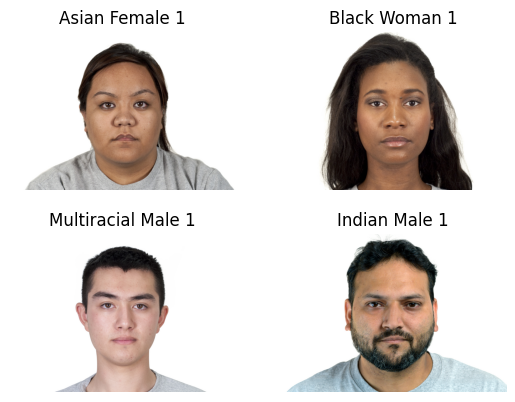

In [17]:
# ==============================================================
# [OPTIONAL] View 4 sample images in a 2x2 grid
# Exploration only. Shows original images are (1718, 2444, 3).
# ==============================================================

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as img

image1 = img.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-208/CFD-AF-208-003-N.jpg')
image2 = img.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BF-243/CFD-BF-243-164-N.jpg')
image3 = img.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD-MR/CFD-MM-306-010-N.jpg')
image4 = img.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA/CFD-IM-645-001-N.jpg')

#creating figure to display multiple imgs from dataset at once
fig, axs = plt.subplots(2, 2)

axs[0,0].imshow(image1)
axs[0,0].set_title('Asian Female 1')
axs[0,0].set_axis_off()

axs[0,1].imshow(image2)
axs[0,1].set_title('Black Woman 1')
axs[0,1].set_axis_off()

axs[1,0].imshow(image3)
axs[1,0].set_title('Multiracial Male 1')
axs[1,0].set_axis_off()

axs[1,1].imshow(image4)
axs[1,1].set_title('Indian Male 1')
axs[1,1].set_axis_off()

print(image1.shape) #img dimensions are all (1718, 2444, 3)

(1718, 2444, 3)


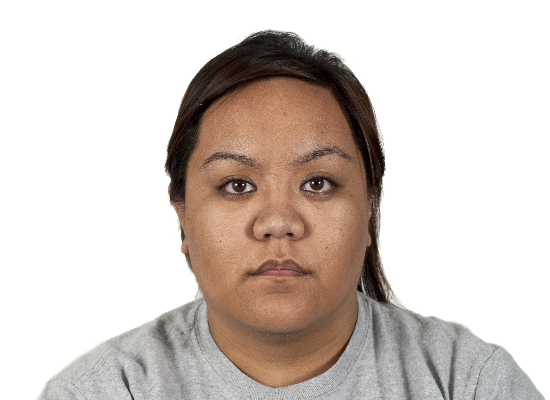

In [18]:
# ==============================================================
# [OPTIONAL] View one image with OpenCV and test a resize
# Exploration only (practice with cv2.imread / cv2.resize).
# ==============================================================

#https://colab.research.google.com/github/dphi-official/Deep_Learning_Bootcamp/blob/master/OpenCV/DL_Day12_OpenCV.ipynb#scrollTo=fppMCwQGI1-w
#cv2 works with cv2_show
import cv2
from google.colab.patches import cv2_imshow

path = ('/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-208/CFD-AF-208-003-N.jpg')

image = cv2.imread(path)
print(image.shape)

resized_image = cv2.resize(image, (550,400))

cv2_imshow(resized_image)
#cv2_imshow(image)

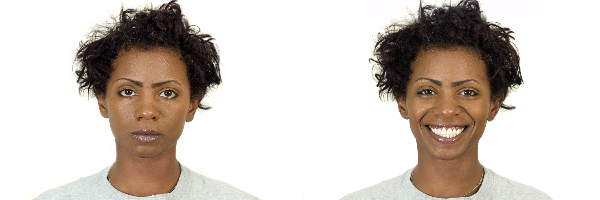

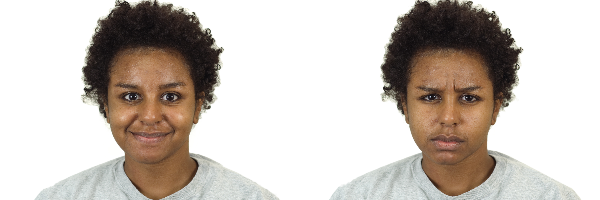

In [20]:
# ==============================================================
# [OPTIONAL] Show 4 resized images side by side (Black female / neutral+expressions)
# Exploration only. Previews what 300x200 resizing looks like.
# ==============================================================

import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image1 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BF-015/CFD-BF-015-004-N.jpg')
image2 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BF-015/CFD-BF-015-006-HO.jpg')
image3 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BF-045/CFD-BF-045-064-HC.jpg')
image4 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BF-045/CFD-BF-045-068-A.jpg')

img1 = cv2.resize(image1, (300,200))
img2 = cv2.resize(image2, (300,200))
img3 = cv2.resize(image3, (300,200))
img4 = cv2.resize(image4, (300,200))

#concatenate image horizontally and vertically
horz = np.concatenate((img1, img2), axis = 1)
vert = np.concatenate((img3, img4), axis = 1)

cv2_imshow(horz)
cv2_imshow(vert)
#cv2.destroyAllWindows()

In [ ]:
# ==============================================================
# [OPTIONAL] Collect the paths of all main-CFD images into cfd_file_names
# Not used later: the image-loading cell (RUN #3) rebuilds its own list.
# Creates: cfd_file_names.
# ==============================================================

import os

main_dir = '/content/drive/MyDrive/CFD_Version_3/Images/CFD'

cfd_file_names = []

for dir_name in os.listdir(main_dir):
  new_path = os.path.join(main_dir + '/' + dir_name)

  for file_name in os.listdir(new_path):
    if 'jpg' in file_name:
      complete_path = os.path.join(new_path + '/' + file_name)
      cfd_file_names.append(complete_path)

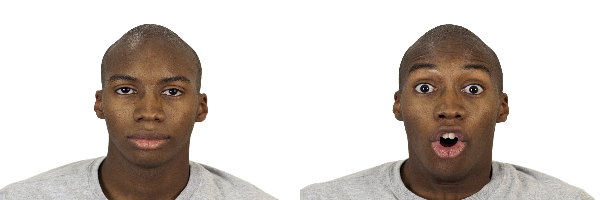

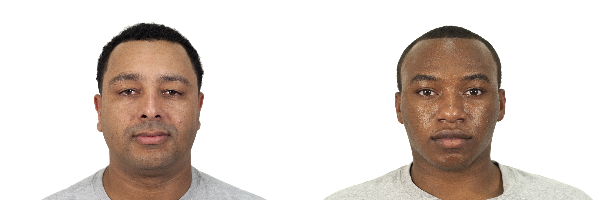

In [21]:
# ==============================================================
# [OPTIONAL] Show 4 resized images side by side (Black male)
# Exploration only. Same idea as the previous cell.
# ==============================================================

import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image1 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BM-036/CFD-BM-036-003-N.jpg')
image2 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BM-036/CFD-BM-036-045-F.jpg')
image3 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BM-222/CFD-BM-222-173-N.jpg')
image4 = cv2.imread('/content/drive/MyDrive/CFD_Version_3/Images/CFD/BM-240/CFD-BM-240-207-N.jpg')

img1 = cv2.resize(image1, (300,200))
img2 = cv2.resize(image2, (300,200))
img3 = cv2.resize(image3, (300,200))
img4 = cv2.resize(image4, (300,200))

#concatenate image horizontally and vertically
horz = np.concatenate((img1, img2), axis = 1)
vert = np.concatenate((img3, img4), axis = 1)

cv2_imshow(horz)
cv2_imshow(vert)
#cv2.destroyAllWindows()

## Note

The code below will read all file names, as they contain the expression that the subject is expressing. This is because we want to see how many of images in each label is present.

In [ ]:
# ==============================================================
# [OPTIONAL] Print cfd_file_names
# Very long output. Skip unless you want to inspect the paths.
# ==============================================================
print(cfd_file_names)

In [24]:
# ==============================================================
# [OPTIONAL] Print img_cfd_list (the file paths)
# Long output. Skip unless debugging.
# ==============================================================

print(img_cfd_list)

['/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-200/CFD-AF-200-228-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-201/CFD-AF-201-060-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-202/CFD-AF-202-122-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-203/CFD-AF-203-077-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-204/CFD-AF-204-067-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-205/CFD-AF-205-155-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-206/CFD-AF-206-079-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-207/CFD-AF-207-023-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-208/CFD-AF-208-003-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-209/CFD-AF-209-006-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-210/CFD-AF-210-050-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF-211/CFD-AF-211-066-N.jpg', '/content/drive/MyDrive/CFD_Version_3/Images/CFD/AF

In [ ]:
# ==============================================================
# [SKIP] First attempt at listing the CFD-INDIA images (has a bug)
# Uses 'file_name' left over from an earlier cell. Replaced by the next cell.
# ==============================================================

import os

ind_dir = '/content/drive/MyDrive/CFD Version 3.0/Images/CFD-INDIA'

ind_folder = []

#each time the for loop is run, the list is appended once again even though the same information was already in there

ind_folder.clear()

for ind_name in os.listdir(ind_dir):
  new_ind_path = os.path.join(ind_dir + '/' + ind_name)
  ind_folder.append(new_ind_path)


  #print(new_ind_path)

#at this point, the ind_folder list has all the images from the CFD-INDIA folder
#but have not passed through the four other folders and added those images to the img_folder[] list

#now I have to use the nested loop approach for the four folders:

remain_1 = '/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA/CFD-IF-644-306'
remain_2 = '/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA/CFD-IF-677-452'
remain_3 = '/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA/CFD-IF-714-008'
remain_4 = '/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA/CFD-IM-638-250'

for x in os.listdir(remain_1):
  if 'jpg' in file_name:
    two_ind_path = os.path.join(remain_1 + '/' + x)
    ind_folder.append(two_ind_path)

for x in os.listdir(remain_2):
  if 'jpg' in file_name:
    three_ind_path = os.path.join(remain_2 + '/' + x)
    ind_folder.append(three_ind_path)

for x in os.listdir(remain_3):
  if 'jpg' in file_name:
    four_ind_path = os.path.join(remain_3 + '/' + x)
    ind_folder.append(four_ind_path)

for x in os.listdir(remain_4):
  if 'jpg' in file_name:
    fifth_ind_path = os.path.join(remain_4 + '/' + x)
    ind_folder.append(fifth_ind_path)

  # for file_name in os.listdir(two_ind_path):
  #   if 'jpg' in file_name:
  #     ind_path = os.path.join(two_ind_path + '/' + file_name)
  #     ind_folder.append(two_ind_path)


In [ ]:
# ==============================================================
# [SKIP] Second attempt at listing the CFD-INDIA images
# Builds ind_folder, which nothing else uses. The India array is built
# separately further down.
# ==============================================================

import os

ind_dir = '/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA'

ind_folder = []

#each time the for loop is run, the list is appended once again even though the same information was already in there
#ind_folder.clear()

for ind_name in os.listdir(ind_dir):
  if 'jpg' in ind_name:
    new_ind_path = os.path.join(ind_dir + '/' + ind_name)
    ind_folder.append(new_ind_path)
  else:
    sub_ind_dir =  os.path.join(ind_dir + '/' + ind_name)
    for sub_ind_name in os.listdir(sub_ind_dir):
      sub_ind_path =  os.path.join(sub_ind_dir + '/' + sub_ind_name)
      ind_folder.append(sub_ind_path)

# for sub_ind_name in os.listdir(sub_ind_dir):
#   sub_ind_path =  os.path.join(sub_ind_dir + '/' + sub_ind_name)
#   ind_folder.append(sub_ind_path)

In [ ]:
# ==============================================================
# [SKIP] Print ind_folder
# Debugging output.
# ==============================================================

print(ind_folder)

In [ ]:
# ==============================================================
# [SKIP] Check whether one India file path is in ind_folder
# Debugging check.
# ==============================================================

if '/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA/CFD-IF-644-306/CFD-IF-644-306-1-N.jpg' in ind_folder:
  print('true')
else:
  print('false')

false


In [ ]:
# ==============================================================
# [SKIP] List the CFD-MR folder contents into mr_folder
# Not used later. Debugging/exploration.
# ==============================================================

import os

mr_main = '/content/drive/MyDrive/CFD_Version_3/Images/CFD-MR'

mr_folder = []
mr_folder.clear()

for name in os.listdir(mr_main):
  mr_path = os.path.join(mr_main + '/' + name)
  mr_folder.append(mr_path)

print(mr_folder)

## Note

Labels are found by splitting the name of the image down by separating each part at the hyphen, then we use [-1] and [0] to find the name/value of the emotion of that image. the -1 is used to find the first value/object at the end. 0 is used to find the first object of that value which is 'N' or another letter representing another emotion.  

Counter({'N': 597, 'H': 307, 'A': 154, 'F': 149})


Text(0.5, 1.0, 'Distribution of Labels')

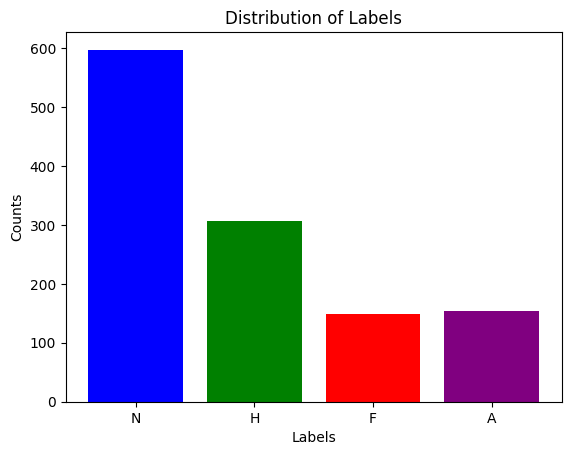

In [ ]:
# ==============================================================
# [OPTIONAL (recommended)] Bar chart of how many images per emotion (class skew)
# Shows Neutral dominates: N 597, H 307, A 154, F 149.
# Needs: RUN #4.
# ==============================================================

from collections import Counter
import matplotlib.pyplot as plt

label_cfd_count = Counter(labels_cfd)
print(label_cfd_count)

labels, values = zip(*label_cfd_count.items())
plt.bar(labels, values, color=['blue', 'green', 'red', 'purple'])

# Add labels and title
plt.xlabel('Labels')
plt.ylabel('Counts')
plt.title('Distribution of Labels')

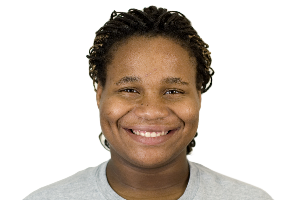

H
(1207, 200, 300, 3)
1207


In [ ]:
# ==============================================================
# [OPTIONAL (recommended)] Sanity check: show one image, its label, and the array shape
# After the axis=0 fix, the shape should print (1207, 200, 300, 3)
# and the label count should be 1207.
# Needs: RUN #3 and #4.
# ==============================================================

from google.colab.patches import cv2_imshow

cv2_imshow(data_cfd_array[207])
print(labels_cfd[207])

#number of images and size

print(data_cfd_array.shape)
print(len(labels_cfd))

In [ ]:
# ==============================================================
# [OPTIONAL] Load + resize the CFD-INDIA subset into data_cfd_india_array
# A separate dataset. NOT used in training unless you merge it in
# yourself. Creates: img_cfd_india_list, data_cfd_india_array.
# ==============================================================

#extracting labels for CFD_India folder and resizing the images in this folder

import os
import cv2
import numpy as np

%cd "/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA"
main_dir = "/content/drive/MyDrive/CFD_Version_3/Images/CFD-INDIA"
count = 0

img_cfd_india_list = []
data_cfd_india_list = []
target_size = (300,200)

for file_name in os.listdir(main_dir):
  if 'jpg' in file_name:
    ext_path = os.path.join(main_dir + "/" + file_name)
  # for img_name in os.listdir(ext_path):
    print(count)
    # full_path = os.path.join(ext_path + img_name)
    img_new = cv2.imread(ext_path)
    img_resized = cv2.resize(img_new, target_size)
    data_cfd_india_list.append(img_resized)
    img_cfd_india_list.append(ext_path)
    count += 1

data_cfd_india_array = np.stack(data_cfd_india_list, axis=0)

In [ ]:
# ==============================================================
# [OPTIONAL] Print img_cfd_india_list
# Long output. Debugging.
# ==============================================================

print(img_cfd_india_list)

In [ ]:
# ==============================================================
# [OPTIONAL] Extract labels for the India subset
# Creates: labels_cfd_india.
# ==============================================================

labels_cfd_india = [path.split('-')[-1][0] for path in img_cfd_india_list]

print(labels_cfd_india)

['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


Counter({'N': 146})


Text(0.5, 1.0, 'Distribution of Labels in Indian Dataset')

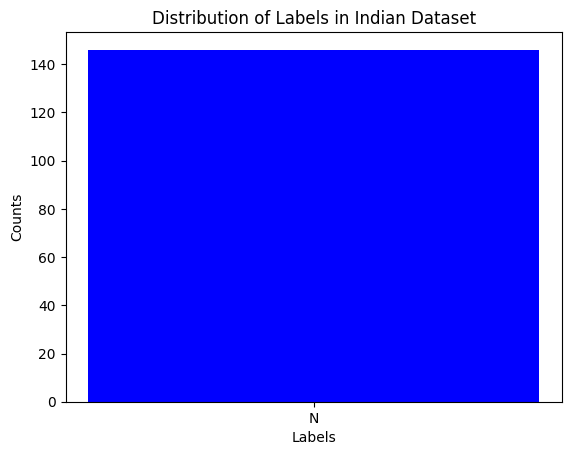

In [ ]:
# ==============================================================
# [OPTIONAL] Bar chart of label counts for the India subset
# Shows class skew.
# ==============================================================
#graph to depict the skew in the data

from collections import Counter
import matplotlib.pyplot as plt

label_cfd_ind_count = Counter(labels_cfd_india)
print(label_cfd_ind_count)

labels, values = zip(*label_cfd_ind_count.items())
plt.bar(labels, values, color=['blue', 'green', 'red', 'purple'])

# Add labels and title

plt.xlabel('Labels')
plt.ylabel('Counts')
plt.title('Distribution of Labels in Indian Dataset')

In [ ]:
# ==============================================================
# [OPTIONAL] Load + resize the CFD-MR (multiracial) subset into data_cfd_mr_array
# A separate dataset. NOT used in training unless you merge it in.
# Creates: img_cfd_mr_list, data_cfd_mr_array.
# ==============================================================

#extracting labels for CFD_MR folder and resizing the images in this folder

import os
import cv2
import numpy as np

%cd "/content/drive/MyDrive/CFD_Version_3/Images/CFD-MR"
main_dir = "/content/drive/MyDrive/CFD_Version_3/Images/CFD-MR"
count = 0

img_cfd_mr_list = []
data_cfd_mr_list = []
target_size = (300,200)

for file_name in os.listdir(main_dir):
  if 'jpg' in file_name:
    ext_path = os.path.join(main_dir + "/" + file_name)
  # for img_name in os.listdir(ext_path):

    print(count)

    # full_path = os.path.join(ext_path + img_name)
    img_new = cv2.imread(ext_path)
    img_resized = cv2.resize(img_new, target_size)
    data_cfd_mr_list.append(img_resized)
    img_cfd_mr_list.append(ext_path)
    count += 1

data_cfd_mr_array = np.stack(data_cfd_mr_list, axis=0)

In [ ]:
# ==============================================================
# [OPTIONAL] Print img_cfd_mr_list
# Long output. Debugging.
# ==============================================================

print(img_cfd_mr_list)

In [ ]:
# ==============================================================
# [OPTIONAL] Extract labels for the MR subset
# Creates: labels_cfd_mr.
# ==============================================================

labels_cfd_mr = [path.split('-')[-1][0] for path in img_cfd_mr_list]

print(labels_cfd_mr)

['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


Counter({'N': 88})


Text(0.5, 1.0, 'Dist. of Labels in Multiracial Dataset')

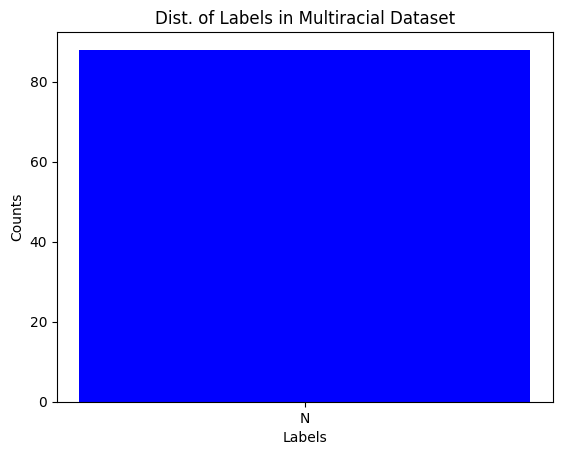

In [ ]:
# ==============================================================
# [OPTIONAL] Bar chart of label counts for the MR subset
# Shows class skew.
# ==============================================================

#graph to depict the skew in the data

from collections import Counter
import matplotlib.pyplot as plt

label_cfd_mr_count = Counter(labels_cfd_mr)
print(label_cfd_mr_count)

labels, values = zip(*label_cfd_mr_count.items())
plt.bar(labels, values, color=['blue', 'green', 'red', 'purple'])

# Add labels and title
plt.xlabel('Labels')
plt.ylabel('Counts')
plt.title('Dist. of Labels in Multiracial Dataset')

#Resources:

## Streamlit:
https://streamlit.io/gallery?category=favorites

https://cheat-sheet.streamlit.app/


## Ngrok/localtunnel:
video tutorial: https://www.youtube.com/watch?v=NEhrkeF2o_M

https://discuss.streamlit.io/t/how-to-launch-streamlit-app-from-google-colab-notebook/42399

https://pypi.org/project/py-localtunnel/

https://discuss.streamlit.io/t/how-to-launch-streamlit-app-from-google-colab-notebook/42399/3